# ABS data at SA2 level, and putting consumers on the map

**What this notebook is for.** Our consumers come with a postcode and nothing else.
Postcodes are a delivery convenience invented by Australia Post — they are not a
statistical geography, they have no official boundaries, and the ABS publishes very
little on them. Most of what we want (socio-economic indexes, and any boundary we can
actually draw a map with) is published on **SA2s**: Statistical Area Level 2, roughly
a suburb or a group of suburbs, around 3,000-25,000 people each, 2,472 of them
covering Australia.

So this notebook does two things:

1. Builds a bridge from postcode to SA2, and is honest about how lossy that bridge is.
2. Shows what the SA2 data looks like, and what it lets us say about our customers
   that the transaction data alone cannot.

The code that produces these tables is in `scripts/download_external_sa2.py`; this
notebook reads its output and explains it.

> Run `python scripts/download_external_sa2.py` first if the tables below are missing.

In [1]:
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import pandas as pd

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
PROCESSED = PROJECT_ROOT / "data" / "tables" / "processed"
EXTERNAL = PROJECT_ROOT / "data" / "tables" / "external"

census = pd.read_parquet(PROCESSED / "abs_census_sa2")
correspondence = pd.read_parquet(PROCESSED / "abs_poa_sa2_correspondence")
primary = pd.read_parquet(PROCESSED / "abs_poa_sa2_primary")

print(f"{len(census):,} SA2s")
print(f"{len(primary):,} postcodes")
print(f"{len(correspondence):,} postcode x SA2 pairs")

2,472 SA2s
2,644 postcodes
5,904 postcode x SA2 pairs


## 1. What the ABS gives us per SA2

Two sources, joined on the SA2 code:

- **2021 Census** (tables G01 and G02): population, median age, median personal and
  household income, median rent and mortgage repayment.
- **SEIFA 2021**: four indexes built from ~30 census variables and standardised to a
  mean of 1000. The one we will lean on is **IRSAD** (Index of Relative Socio-economic
  Advantage and Disadvantage) — high means an area has more high-income, highly
  qualified, professionally employed households, low means the opposite. It is a
  better single summary of "can these customers absorb a missed instalment" than
  income alone, because it also carries employment and education.

In [2]:
census.sample(6, random_state=0)[[
    "sa2_code", "sa2_name", "abs_population",
    "abs_median_household_income_weekly", "abs_median_rent_weekly",
    "seifa_irsad_score", "seifa_irsad_decile",
]]

,sa2_code,sa2_name,abs_population,abs_median_household_income_weekly,abs_median_rent_weekly,seifa_irsad_score,seifa_irsad_decile
805,206071145,Clifton Hill - Alphington,9855,2529.0,500.0,1143.0,10.0
1675,318021490,Townsville City - North Ward,9116,1783.0,320.0,1052.0,8.0
1735,401061020,Nailsworth - Broadview,6484,1967.0,320.0,1053.0,8.0
1597,316011413,Buderim - North,17960,1583.0,460.0,1035.0,7.0
1188,301031020,Wynnum,14502,1882.0,400.0,1030.0,7.0
2350,801011021,McKellar,2740,2687.0,438.0,1079.0,9.0


## 2. How cleanly do postcodes sit inside SA2s?

Neither geography respects the other, so the join has to be built from below. Both
postal areas and SA2s are made of **Mesh Blocks** — the smallest ABS unit, about
370,000 of them, typically 30-60 dwellings. Laying the two allocation files over each
other gives every postcode/SA2 overlap, and the 2021 Census Mesh Block counts give the
population living in each one. A postcode's population split across SA2s is the
weight.

Each consumer is then assigned the SA2 holding the **largest share** of their
postcode's population, and we keep that share (`sa2_share`) as a confidence weight.

In [3]:
split = primary["n_sa2s"].value_counts().sort_index()
summary = pd.DataFrame({
    "postcodes": [
        (primary["n_sa2s"] == 1).sum(),
        primary["n_sa2s"].between(2, 5).sum(),
        (primary["n_sa2s"] > 5).sum(),
    ],
}, index=["1 SA2", "2-5 SA2s", "6+ SA2s"])
summary["share of postcodes"] = (summary["postcodes"] / len(primary)).map("{:.1%}".format)
summary

,postcodes,share of postcodes
1 SA2,1192,45.1%
2-5 SA2s,1307,49.4%
6+ SA2s,145,5.5%


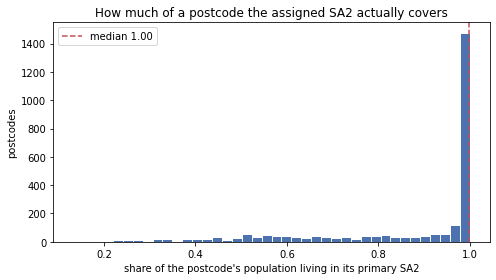

In [4]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(primary["sa2_share"], bins=40, color="#4c72b0", edgecolor="white")
ax.set_xlabel("share of the postcode's population living in its primary SA2")
ax.set_ylabel("postcodes")
ax.set_title("How much of a postcode the assigned SA2 actually covers")
ax.axvline(primary["sa2_share"].median(), color="#c44e52", linestyle="--",
           label=f"median {primary['sa2_share'].median():.2f}")
ax.legend()
plt.tight_layout()
plt.show()

**Reading this.** The spike at 1.0 is the good case: the postcode sits wholly inside one
SA2, so the ABS figures we attach to those consumers are exactly right. The left tail is
the problem case — mostly large rural postcodes that span several SA2s, where the
assigned SA2 describes only a minority of the postcode and the attached income figure
is a blur.

This is why `sa2_share` travels with every consumer instead of being thrown away. When
we aggregate customer income up to a merchant, weighting by `sa2_share` lets the
confident rows count for more.

In [5]:
worst = primary.nlargest(1, "n_sa2s").iloc[0]
print(f"Most split postcode: {worst['postcode']} ({worst['sa2_name']}, {worst['state_name']})")
print(f"spread over {worst['n_sa2s']} SA2s; the primary one holds {worst['sa2_share']:.1%} of its people\n")

(correspondence[correspondence["postcode"] == worst["postcode"]]
 .nlargest(8, "weight")[["sa2_code", "sa2_name", "persons", "weight"]]
 .assign(weight=lambda d: d["weight"].map("{:.1%}".format))
 .reset_index(drop=True))

Most split postcode: 2611 (Coombs, Australian Capital Territory)
spread over 21 SA2s; the primary one holds 13.3% of its people



,sa2_code,sa2_name,persons,weight
0,801101135,Coombs,4834,13.3%
1,801081098,Weston,3983,10.9%
2,801101139,Wright,3791,10.4%
3,801081092,Duffy,3397,9.3%
4,801081095,Rivett,3376,9.3%
5,801081093,Fisher,3201,8.8%
6,801081091,Chapman,2863,7.9%
7,801081094,Holder,2815,7.7%


It happens in the city too, and closer to home for the presentation: postcode 3000
(Melbourne CBD) splits across five SA2s, none of which holds even 40% of it.

In [6]:
(correspondence[correspondence["postcode"] == "3000"]
 .nlargest(5, "weight")[["sa2_code", "sa2_name", "persons", "weight"]]
 .assign(weight=lambda d: d["weight"].map("{:.1%}".format))
 .reset_index(drop=True))

,sa2_code,sa2_name,persons,weight
0,206041504,Melbourne CBD - North,16872,39.2%
1,206041505,Melbourne CBD - West,15652,36.3%
2,206041503,Melbourne CBD - East,9838,22.8%
3,206041117,Carlton,614,1.4%
4,206041506,North Melbourne,105,0.2%


### Postcodes with no residents at all

Some postcodes have mesh blocks but no people in them — PO box ranges, airports,
industrial estates, CBD blocks that are all commercial. Population weighting cannot
work there (every weight would be 0/0), so the script falls back to dwellings, and
then to a plain mesh block count. The `weight_basis` column records which was used, so
nothing silently pretends to be population-weighted when it is not.

In [7]:
primary["weight_basis"].value_counts().rename("postcodes").to_frame()

,postcodes
weight_basis,
persons,2641
mesh_blocks,2
dwellings,1


## 3. What this buys us: maps

With SA2 boundaries we can finally draw the customer base rather than tabulate it.
Greater Melbourne below, because the pattern is legible at that scale; the same code
works nationally.

376 SA2s in the Greater Melbourne bounding box


ImportError: The 'mapclassify' package is required to use the 'scheme' keyword.

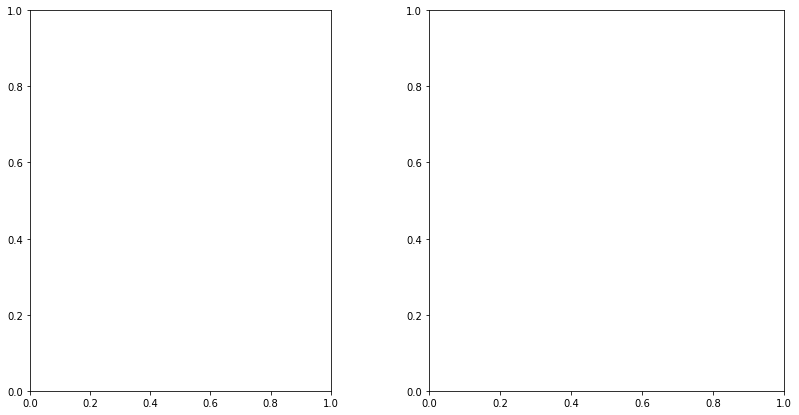

In [9]:
boundaries = gpd.read_file(EXTERNAL / "SA2_2021_AUST_simplified.geojson")
melbourne = boundaries.cx[144.4:145.6, -38.4:-37.4].merge(census, on="sa2_code", how="left")
print(f"{len(melbourne):,} SA2s in the Greater Melbourne bounding box")

fig, axes = plt.subplots(1, 2, figsize=(14, 7))
for ax, column, title in [
    (axes[0], "abs_median_household_income_weekly", "Median household income ($/week)"),
    (axes[1], "seifa_irsad_score", "SEIFA IRSAD score (1000 = national mean)"),
]:
    melbourne.plot(
        column=column, ax=ax, cmap="viridis", legend=True, scheme="Quantiles", k=6,
        missing_kwds={"color": "#eeeeee", "label": "no data"},
        edgecolor="white", linewidth=0.1,
    )
    ax.set_title(title)
    ax.set_axis_off()
    ax.get_legend().set_bbox_to_anchor((0.35, 0.35))
plt.tight_layout()
plt.show()

The two maps agree on the broad shape — the inner east and bayside suburbs sit high on
both, the outer west and north sit low — but they are not the same picture, and the
places they disagree are the interesting ones. IRSAD also carries education and
occupation, so areas with modest incomes but high qualifications (student-heavy inner
suburbs) score higher on IRSAD than on income alone. For a credit product, that
difference matters: qualified renters on low current income are a different risk from
low-income households with no qualifications.

`viridis` is used throughout because it stays monotonic in greyscale and is readable
with the common forms of colour blindness — worth keeping consistent across the
presentation slides.

## 4. Our consumers, once they are placed

The section below only runs once `scripts/join_external_sa2.py` has been run over the
Canvas data (it needs `tbl_consumer.csv` and `consumer_user_details.parquet`, which are
gitignored). It is the bridge from this notebook to the ranking work: the per-merchant
customer-quality features in `docs/ranking_system_brainstorm.md` are all built from
this table.

In [ ]:
consumers_path = PROCESSED / "consumers_sa2"

if not consumers_path.exists():
    print("consumers_sa2 not found - run scripts/join_external_sa2.py first.")
else:
    consumers = pd.read_parquet(consumers_path)
    matched = consumers["sa2_matched"].mean()
    print(f"{len(consumers):,} consumers, {matched:.1%} placed in an SA2")

    by_sa2 = (consumers[consumers["sa2_matched"]]
              .groupby(["sa2_code"], as_index=False)
              .agg(consumers=("user_id", "count"),
                   median_income=("abs_median_household_income_weekly", "median"),
                   irsad=("seifa_irsad_score", "median")))

    melb_consumers = boundaries.cx[144.4:145.6, -38.4:-37.4].merge(by_sa2, on="sa2_code", how="left")
    fig, ax = plt.subplots(figsize=(8, 8))
    melb_consumers.plot(column="consumers", ax=ax, cmap="viridis", legend=True,
                        scheme="Quantiles", k=6,
                        missing_kwds={"color": "#eeeeee", "label": "no consumers"},
                        edgecolor="white", linewidth=0.1)
    ax.set_title("Consumers per SA2, Greater Melbourne")
    ax.set_axis_off()
    plt.tight_layout()
    plt.show()

    display(by_sa2.nlargest(10, "consumers")
            .merge(census[["sa2_code", "sa2_name"]], on="sa2_code")
            [["sa2_name", "consumers", "median_income", "irsad"]])

## 5. Findings and limitations

**Findings**

- A bridge from postcode to SA2 now exists at Mesh Block resolution, population
  weighted, covering all 2,644 postal areas the ABS recognises.
- Postcodes line up with SA2s better than expected but not cleanly: 45% sit wholly
  inside a single SA2, and 65% have a primary SA2 covering 90% or more of their people.
- The remaining 10% — those whose primary SA2 covers under half the postcode, largely
  rural — are where this gets lossy. Any statement we make about "customers in area X"
  is a statement about the primary SA2, and should be weighted by `sa2_share`.
- SEIFA is now available per consumer, which is the piece the transaction data could
  never give us: a measure of whether a customer base can carry a credit product.

**Limitations, in order of how much they should worry us**

1. **Consumer addresses are synthetic.** The postcodes are plausibly distributed but
   they were generated, not observed, so the geography describes a simulated
   population. Every conclusion is conditional on that.
2. **Postcodes are not SA2s.** Assigning the dominant SA2 is the best available answer,
   not a correct one. `sa2_share` quantifies the damage; use it as a weight, and do not
   quote SA2-level figures for individual consumers as if they were personal attributes.
3. **PO box and commercial postcodes have no residents** and fall back to dwelling or
   mesh-block weighting, which is materially weaker. Those consumers should probably be
   treated as unmatched for any income-based feature.
4. **The Census is 2021**; transactions run to August 2022. Incomes and rents have moved
   since, unevenly by area. Fine for ranking areas against each other, wrong for
   absolute dollar claims.
5. **Ecological fallacy.** An SA2's median income is a property of the area, not of the
   customer living there. It is a prior, not a fact about the person.

**Next**

Build the per-merchant customer-quality features on top of `consumers_sa2` —
population-weighted customer income, mean IRSAD, geographic spread — as set out in
`docs/ranking_system_brainstorm.md`.